# Experiment 9 (Mini Project): Cyberbullying Detection in Hinglish Social Media Posts

**Task:** Multiclass text classification. Given a short Hinglish (Hindi + English, code-mixed) social media post, predict which of **7 classes** it belongs to:
`not_cyberbullying`, `gender`, `religion`, `age`, `abusive`, `offensive`, `mockery`.

**Dataset:** [MC-Hinglish1.0](https://huggingface.co/datasets/sahinurlaskar/MC-Hinglish1.0) (Hugging Face, CC BY-NC-SA 4.0)

**Pipeline:**
1. Data Collection
2. Data Processing & Feature Extraction (cleaning, tokenization, TF-IDF)
3. Model Training (Naive Bayes, Logistic Regression, Linear SVM)
4. Evaluation (accuracy, precision, recall, F1, confusion matrix)

## 1. Data Collection

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")
RESULTS = "results"

# The CSVs are included in data/. They can also be downloaded from:
# https://huggingface.co/datasets/sahinurlaskar/MC-Hinglish1.0
train_df = pd.read_csv("data/Train_data_MC-Hinglish1.0.csv")
test_df  = pd.read_csv("data/Test_data_MC-Hinglish1.0.csv")

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
train_df.head(10)

Train shape: (7400, 2)
Test shape : (1000, 2)


,tweets,cyberbullying_type
0,Foundation X Aata,mockery
1,Foundation X Cement,mockery
2,Chunna laga diya got real,offensive
3,"Didi show off krri h ""Left hand rule""",gender
4,Matak ke chalungi X Matka chalega,offensive
5,Dress ne apna color chod diya didi ke upar,gender
6,Bhaiya gutka toh thukne dete didi ko,gender
7,52 Gaj X 52 Gaj ki aurat,gender
8,Bhaiya face pe wall putty krdo got real,offensive
9,52 kilo ka aata lagaya h didi ne,gender


In [2]:
print("Missing values (train):")
print(train_df.isna().sum())
print("\nDuplicate rows (train):", train_df.duplicated().sum())

Missing values (train):
tweets                1
cyberbullying_type    0
dtype: int64

Duplicate rows (train): 7


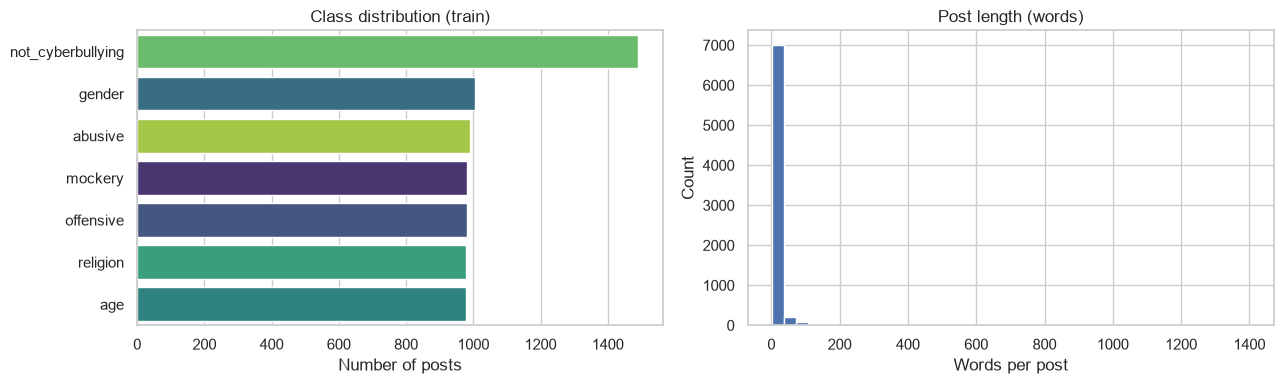

Average words per post: 18.91


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = train_df["cyberbullying_type"].value_counts().index
sns.countplot(data=train_df, y="cyberbullying_type", order=order, ax=axes[0], hue="cyberbullying_type", legend=False, palette="viridis")
axes[0].set_title("Class distribution (train)")
axes[0].set_xlabel("Number of posts"); axes[0].set_ylabel("")

lengths = train_df["tweets"].astype(str).str.split().str.len()
axes[1].hist(lengths, bins=40, color="#4c72b0")
axes[1].set_title("Post length (words)")
axes[1].set_xlabel("Words per post"); axes[1].set_ylabel("Count")
plt.tight_layout()
plt.savefig(f"{RESULTS}/class_distribution.png", dpi=150)
plt.show()

print("Average words per post:", round(lengths.mean(), 2))

## 2. Data Processing & Feature Extraction

Hinglish text is informal: mixed scripts, inconsistent spellings (`nahi` / `nai` / `nhi`), emojis, mentions and URLs.
Cleaning steps:
- drop missing / duplicate rows
- lowercase
- remove URLs, @mentions, `#` symbol (keep the hashtag word), numbers and punctuation
- squeeze repeated characters (`sooooo` → `soo`)
- tokenize on whitespace and remove a small list of common English + Hindi stop-words

We don't use stemming/lemmatization because standard stemmers are English-only and break Romanized Hindi words.

In [4]:
STOPWORDS = set('''
a an the is are was were be been am i me my you your he she it we they them this that these those
of to in on at for with and or but so if as by from up out do does did have has had not no
hai hain ho tha thi the ka ki ke ko se me mein par aur ya bhi to toh ye yeh wo woh ek kya
'''.split())

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # URLs
    text = re.sub(r"@\w+", " ", text)                     # mentions
    text = text.replace("#", " ")                          # keep hashtag word
    text = re.sub(r"[^a-z\u0900-\u097f\s]", " ", text)   # keep English + Devanagari letters
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)            # sooooo -> soo
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    return [w for w in text.split() if w not in STOPWORDS and len(w) > 1]

def preprocess(df):
    df = df.dropna(subset=["tweets"]).drop_duplicates().copy()
    df["clean"] = df["tweets"].apply(clean_text).apply(lambda t: " ".join(tokenize(t)))
    return df[df["clean"].str.len() > 0]

train_df = preprocess(train_df)
test_df  = preprocess(test_df)
print("After cleaning -> train:", train_df.shape, "| test:", test_df.shape)

train_df[["tweets", "clean", "cyberbullying_type"]].sample(8, random_state=1)

After cleaning -> train: (7392, 3) | test: (1000, 3)


,tweets,clean,cyberbullying_type
6621,bc tujhe nhi aati Sharam,bc tujhe nhi aati sharam,abusive
5116,"Tumhara sense of style ekdum next level hai, t...",tumhara sense style ekdum next level trendsett...,not_cyberbullying
3877,Mc bhi karti hai message kesi ladki group pe.,mc karti message kesi ladki group pe,gender
119,Inn musalmaano se bache paida krne ke alwa or ...,inn musalmaano bache paida krne alwa kuch kaam...,religion
5902,Music concerts mein crowd ke energy dekh kar t...,music concerts crowd energy dekh kar dil sukoo...,not_cyberbullying
1753,"Dekh aunty, tu toh lagti hai jaise abhi bhi sc...",dekh aunty tu lagti jaise abhi school computer...,age
4874,"Hindu-Muslim bhai bhai, lekin ek dharam-dhwaj ...",hindu muslim bhai bhai lekin dharam dhwaj aank...,religion
4320,background audio off karde na bsdk,background audio off karde na bsdk,offensive


**Feature extraction - TF-IDF.** Two complementary TF-IDF representations are combined:
- **Word n-grams (1-2):** captures words and short phrases such as `budhha ho gaya`.
- **Character n-grams (2-5):** robust to the spelling variations common in Hinglish (`nahi` / `nhi` share sub-strings).

In [5]:
X_train, y_train = train_df["clean"], train_df["cyberbullying_type"]
X_test,  y_test  = test_df["clean"],  test_df["cyberbullying_type"]

def make_features():
    return FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ])

demo = make_features().fit(X_train)
print("Total TF-IDF features:", len(demo.get_feature_names_out()))

Total TF-IDF features: 102308


## 3. Model Training

Three classic, fast and interpretable classifiers are trained on the same TF-IDF features:

| Model | Why |
|---|---|
| Multinomial Naive Bayes | Standard baseline for text classification |
| Logistic Regression | Strong linear model, gives class probabilities |
| Linear SVM | Usually the best linear model for sparse high-dimensional text |

In [6]:
models = {
    "Naive Bayes":         MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10, class_weight="balanced"),
    "Linear SVM":          LinearSVC(C=1.0, class_weight="balanced"),
}

pipelines, results = {}, []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", make_features()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    pipelines[name] = pipe
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro"),
        "Recall":    recall_score(y_test, pred, average="macro"),
        "Macro F1":  f1_score(y_test, pred, average="macro"),
    })
    print(f"Trained {name}")

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.to_csv(f"{RESULTS}/model_comparison.csv")
results_df

Trained Naive Bayes


Trained Logistic Regression


Trained Linear SVM


,Accuracy,Precision,Recall,Macro F1
Model,,,,
Naive Bayes,0.695,0.6786,0.6820,0.6706
Logistic Regression,0.740,0.7298,0.7293,0.7255
Linear SVM,0.752,0.7401,0.7407,0.7360


## 4. Evaluation

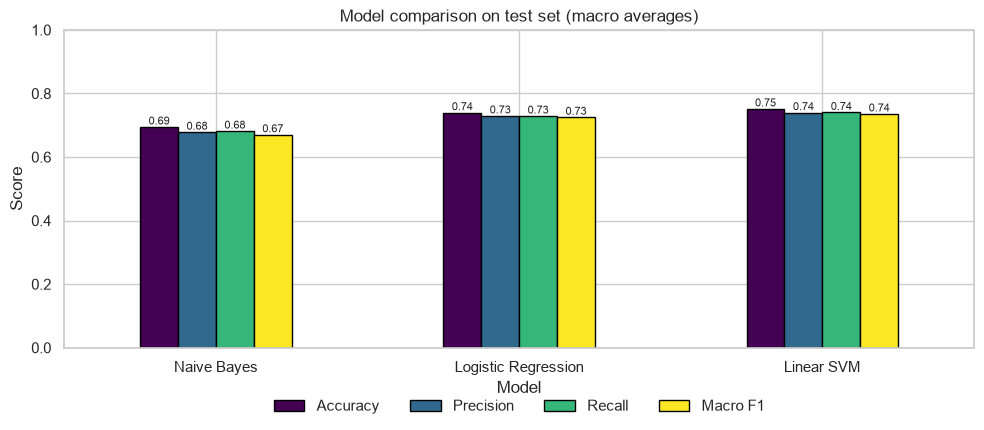

In [7]:
ax = results_df.plot(kind="bar", figsize=(10, 4.5), rot=0, colormap="viridis", edgecolor="black")
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Model comparison on test set (macro averages)")
ax.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.12), frameon=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS}/model_comparison.png", dpi=150)
plt.show()

In [8]:
best_name = results_df["Macro F1"].idxmax()
best = pipelines[best_name]
best_pred = best.predict(X_test)
print(f"Best model: {best_name}\n")
print(classification_report(y_test, best_pred, digits=3))

Best model: Linear SVM

                   precision    recall  f1-score   support

          abusive      0.850     0.649     0.736       148
              age      0.826     0.922     0.872       129
           gender      0.735     0.809     0.770       141
          mockery      0.475     0.378     0.421       127
not_cyberbullying      0.767     0.890     0.824       200
        offensive      0.675     0.621     0.647       124
         religion      0.851     0.916     0.882       131

         accuracy                          0.752      1000
        macro avg      0.740     0.741     0.736      1000
     weighted avg      0.745     0.752     0.744      1000



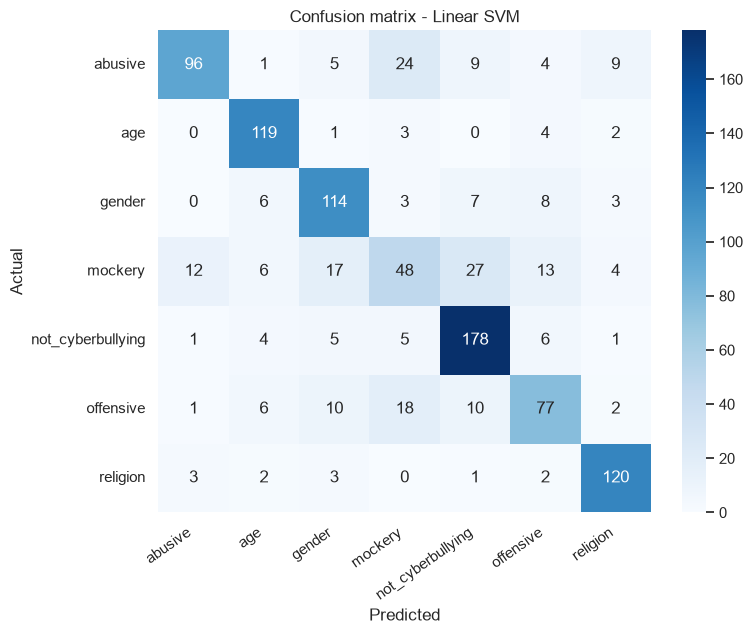

In [9]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, best_pred, labels=labels)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion matrix - {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(f"{RESULTS}/confusion_matrix.png", dpi=150)
plt.show()

### Most informative words per class
For the linear model we can inspect which word features push a post towards each class.

In [10]:
lr = pipelines["Logistic Regression"]
feat_names = lr.named_steps["tfidf"].get_feature_names_out()
word_mask = np.array([f.startswith("word__") for f in feat_names])
coefs = lr.named_steps["clf"].coef_

top_words = {}
for i, cls in enumerate(lr.named_steps["clf"].classes_):
    c = np.where(word_mask, coefs[i], -np.inf)
    idx = np.argsort(c)[::-1][:8]
    top_words[cls] = [feat_names[j].replace("word__", "") for j in idx]
pd.DataFrame(top_words).T.rename(columns=lambda i: f"#{i+1}")

,#1,#2,#3,#4,#5,#6,#7,#8
abusive,chutiya bhai,chutiya,bhosda,bc,block faggot,gaandu,ass,lund
age,umar,aunty,tum like,age,chacha,abhi,uncle,bache
gender,ling,didi,gay,gender,chakke,banda,hijda,bhn
mockery,yrr,gaye,bhosda re,arrey yaar,bhosda lavde,lavde,bsdk,bhai aapke
not_cyberbullying,tune,dil,dekh kar,tumhara,hi,arey bc,haye,happy
offensive,tu online,online,cunt,dick,bc,lekin real,sahi baat,suck
religion,dharam,bhagwan,dharmik,muslim,dharm,hindu,mandir,church


### Try it on new posts

In [11]:
def predict(texts, model=best):
    cleaned = [" ".join(tokenize(clean_text(t))) for t in texts]
    return pd.DataFrame({"post": texts, "predicted_class": model.predict(cleaned)})

predict([
    "Aaj ka match bahut accha tha, great game guys!",
    "Ladkiyon ko kitchen mein hi rehna chahiye",
    "Buddhe ho gaye ho ab retire ho jao uncle",
    "Wah kya baat hai, tumse zyada smart toh mera phone hai",
    "Tu bilkul pagal hai saale",
])

,post,predicted_class
0,"Aaj ka match bahut accha tha, great game guys!",not_cyberbullying
1,Ladkiyon ko kitchen mein hi rehna chahiye,gender
2,Buddhe ho gaye ho ab retire ho jao uncle,age
3,"Wah kya baat hai, tumse zyada smart toh mera p...",mockery
4,Tu bilkul pagal hai saale,offensive


## Conclusion

- A simple **TF-IDF (word + character n-grams)** representation works well for noisy, code-mixed Hinglish text; character n-grams handle inconsistent spellings.
- Linear models (**Logistic Regression / Linear SVM**) outperform the Naive Bayes baseline.
- The confusion matrix shows the hardest confusions are between closely related classes such as `abusive`, `offensive` and `mockery`, which overlap in meaning.
- **Future work:** fine-tune a multilingual transformer (e.g. mBERT / MuRIL / IndicBERT), and add data augmentation for spelling variants.